# Olist Delivery Delay Analysis & Risk Prioritization

**Pertanyaan bisnis:** Wilayah mana yang perlu diselidiki, dan apakah model bisa menemukan lebih banyak order yang akhirnya telat jika tim hanya bisa mengecek maksimal 20 order per hari?

Prediksi dibuat saat order disetujui. Antrean di notebook adalah simulasi review harian pada data historis.

## 1. Import

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Read Data

Baca dua file ZIP yang masing-masing berisi satu CSV.

In [2]:
root = Path.cwd()
if root.name == "Notebook":
    root = root.parent

data = root / "Data"
df = pd.read_csv(data / "olist_orders_dataset.csv.zip")
customers = pd.read_csv(data / "olist_customers_dataset.csv.zip")

print(f"Baris order: {len(df):,}")
display(df.head(3))
print(f"Baris pelanggan: {len(customers):,}")
display(df["order_status"].value_counts().to_frame("jumlah"))
display(df.isna().sum().to_frame("nilai_kosong"))

Baris order: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


Baris pelanggan: 99,441


,jumlah
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,nilai_kosong
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


**Interpretasi.** Ada 99.441 baris order. Ringkasan status dan null membantu melihat order yang sudah bisa diberi label serta tanggal yang masih kosong.

## 3. Preprocessing Awal

### Gabung data dan ubah tipe tanggal

Tambahkan negara bagian tujuan dengan satu baris per order. Simpan data order mentah untuk cek cakupan EDA.

In [3]:
orders = df.copy()
assert orders["order_id"].is_unique

df = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)
assert len(df) == len(orders)
assert df["order_id"].is_unique

df = df.rename(columns={
    "order_approved_at": "approved_at",
    "order_delivered_customer_date": "delivered_at",
    "order_estimated_delivery_date": "estimated_at",
})

required_dates = ["approved_at", "delivered_at", "estimated_at"]

for col in required_dates + ["order_delivered_carrier_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

### Penanganan null

- Order yang belum diterima berada di luar data berlabel. Dari order yang statusnya sudah diterima, keluarkan baris yang tidak punya tanggal approval, tanggal tiba, atau tanggal estimasi.
- Wilayah kosong diisi dengan kategori tetap `Tidak diketahui`.
- Tanggal serah ke kurir kosong tetap disimpan. Baris tersebut hanya dikecualikan dari analisis durasi per tahap.

In [4]:
cols = required_dates + ["customer_state", "order_delivered_carrier_date"]
null_raw = df[cols].isna().sum()

delivered = df.loc[df["order_status"].eq("delivered")].copy()
print(f"Di luar status delivered: {len(df) - len(delivered):,} order")

null_delivered = delivered[cols].isna().sum()
df = delivered.dropna(subset=required_dates).copy()
print(f"Status delivered, tanggal wajib kosong: {len(delivered) - len(df):,} order")

df["customer_state"] = df["customer_state"].fillna("Tidak diketahui")

display(pd.DataFrame({
    "semua_order": null_raw,
    "status_delivered": null_delivered,
    "setelah_preprocessing": df[cols].isna().sum(),
}))

Di luar status delivered: 2,963 order
Status delivered, tanggal wajib kosong: 22 order


,semua_order,status_delivered,setelah_preprocessing
approved_at,160,14,0
delivered_at,2965,8,0
estimated_at,0,0,0
customer_state,0,0,0
order_delivered_carrier_date,1783,2,1


**Interpretasi.** Ada 22 order berstatus delivered yang dikeluarkan karena tanggal wajib kosong. Satu null di tanggal serah ke kurir tetap ada karena tanggal itu hanya dibutuhkan untuk analisis durasi.

### Buat label risiko telat

Label `late = 1` berarti barang tiba setelah hari estimasi. Order yang tiba pada hari estimasi dihitung tepat waktu.

In [5]:
df["approved_day"] = df["approved_at"].dt.normalize()
df["late"] = (
    df["delivered_at"].dt.normalize() > df["estimated_at"].dt.normalize()
).astype(int)

print(f"Order berlabel yang siap dipakai: {len(df):,}")

Order berlabel yang siap dipakai: 96,456


**Interpretasi.** Ada 96.456 order historis yang bisa diberi label. Nilai 1 berarti tiba setelah tanggal estimasi.

## 4. EDA performa pengiriman

Pakai order yang disetujui Januari–April 2018 untuk membandingkan empat bulan penuh. Semua label yang dipakai di sini sudah diketahui sebelum 1 Juni. Periode uji Juni sampai Agustus disisihkan sejak awal agar temuan EDA tidak dipengaruhi data uji. Cek berapa banyak order yang tercakup sebelum membaca metrik.

### Cakupan data dan distribusi label

In [6]:
eda_start = pd.Timestamp("2018-01-01")
eda_end = pd.Timestamp("2018-05-01")

approved = orders.loc[
    pd.to_datetime(orders["order_approved_at"]).between(
        eda_start, eda_end, inclusive="left"
    )
]
eda = df.loc[
    df["approved_at"].between(eda_start, eda_end, inclusive="left")
    & (df["delivered_at"] < pd.Timestamp("2018-06-01"))
].copy()

eda["days_late"] = (
    eda["delivered_at"].dt.normalize() - eda["estimated_at"].dt.normalize()
).dt.days

print(f"Order disetujui: {len(approved):,}")
print(f"Order dengan label sebelum Juni: {len(eda):,} ({len(eda) / len(approved):.1%})")
display(approved.loc[~approved["order_id"].isin(eda["order_id"]), "order_status"]
        .value_counts().to_frame("di_luar_eda"))

late = eda.loc[eda["late"].eq(1)]
print(f"Order telat: {len(late):,} dari {len(eda):,} ({eda['late'].mean():.1%})")
print(f"Median lama telat: {late['days_late'].median():.0f} hari")
print(f"Telat 7 hari atau lebih: {late['days_late'].ge(7).sum():,} order "
      f"({late['days_late'].ge(7).mean():.1%} dari order telat)")

Order disetujui: 27,959
Order dengan label sebelum Juni: 27,162 (97.1%)


,di_luar_eda
order_status,
shipped,362
canceled,140
unavailable,100
delivered,87
invoiced,58
processing,50


Order telat: 2,873 dari 27,162 (10.6%)
Median lama telat: 7 hari
Telat 7 hari atau lebih: 1,572 order (54.7% dari order telat)


**Interpretasi.** EDA mencakup 97,1% order yang disetujui pada Januari–April. Tingkat telat 10,6% dihitung dari 27.162 order yang punya label.

### Tren bulanan

Lihat persentase dan volume bersamaan. Perubahan persentase membantu menemukan bulan yang layak diperiksa lebih lanjut.

,total_order,order_telat,persen_telat
approved_at,,,
2018-01,6990,396,5.67
2018-02,6532,886,13.56
2018-03,7076,1353,19.12
2018-04,6564,238,3.63


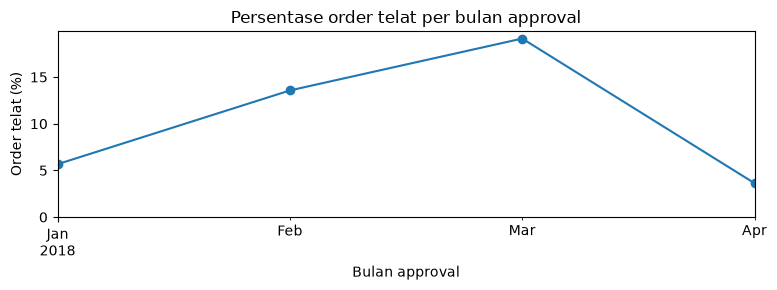

In [7]:
def late_summary(group):
    table = group["late"].agg(total_order="size", order_telat="sum")
    table["persen_telat"] = 100 * table["order_telat"] / table["total_order"]
    return table

monthly = late_summary(eda.groupby(eda["approved_at"].dt.to_period("M")))
display(monthly.round(2))

ax = monthly["persen_telat"].plot(
    figsize=(8, 3), marker="o", ylim=(0, None),
    title="Persentase order telat per bulan approval",
)
ax.set(xlabel="Bulan approval", ylabel="Order telat (%)")
plt.tight_layout()
plt.show()

**Interpretasi.** Maret mencapai 19,1% telat, dibanding 3,6% pada April, dengan volume order yang sebanding. Telusuri Maret per minggu dan wilayah.

### Prioritas negara bagian

Urutkan berdasarkan jumlah order telat untuk melihat dampak. Tampilkan persentase dan kontribusi terhadap seluruh order telat agar keputusan tetap mempertimbangkan volume.

,total_order,order_telat,persen_telat,kontribusi_telat_pct
customer_state,,,,
RJ,3365,734,21.81,25.55
SP,11493,613,5.33,21.34
MG,3245,284,8.75,9.89
RS,1471,166,11.28,5.78
BA,870,158,18.16,5.50
SC,1050,143,13.62,4.98
ES,560,107,19.11,3.72
CE,339,104,30.68,3.62
PR,1446,89,6.15,3.10


Prioritas investigasi: RJ, dengan 734 order telat (25.5% dari seluruh order telat).


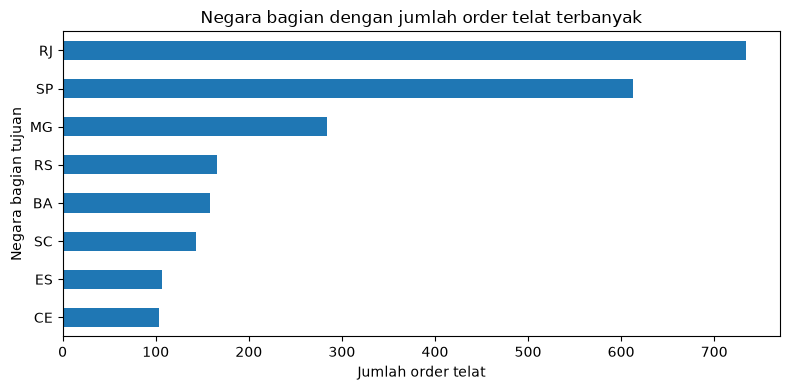

In [8]:
states = late_summary(eda.groupby("customer_state", dropna=False))
states = states.sort_values("order_telat", ascending=False)
states["kontribusi_telat_pct"] = 100 * states["order_telat"] / len(late)
display(states.head(10).round(2))

top_state = states.index[0]
row = states.iloc[0]
print(f"Prioritas investigasi: {top_state}, dengan {row['order_telat']:,.0f} "
      f"order telat ({row['kontribusi_telat_pct']:.1f}% dari seluruh order telat).")

ax = states.head(8)["order_telat"].sort_values().plot.barh(
    figsize=(8, 4), title="Negara bagian dengan jumlah order telat terbanyak"
)
ax.set(xlabel="Jumlah order telat", ylabel="Negara bagian tujuan")
plt.tight_layout()
plt.show()

**Interpretasi.** RJ jadi prioritas berdasarkan dampaknya, yaitu 734 order telat. CE memiliki persentase yang lebih tinggi (30,7%) dengan 104 order telat.

### Rincian kota

Rincian kota membantu menentukan sampel order untuk investigasi. Peringkat ini memakai jumlah order telat, dengan jumlah order dan persentase sebagai konteks.

In [9]:
cities = eda.loc[eda["customer_state"].eq(top_state)].merge(
    customers[["customer_id", "customer_city"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)
city_summary = late_summary(cities.groupby("customer_city", dropna=False))
display(city_summary.sort_values("order_telat", ascending=False).head(10).round(2))

,total_order,order_telat,persen_telat
customer_city,,,
rio de janeiro,1761,335,19.02
niteroi,254,56,22.05
sao goncalo,91,29,31.87
nova iguacu,124,23,18.55
macae,69,22,31.88
cabo frio,40,19,47.50
volta redonda,68,18,26.47
petropolis,74,18,24.32
campos dos goytacazes,71,18,25.35


**Interpretasi.** Kota Rio de Janeiro menyumbang 335 kasus telat, sehingga masuk akal sebagai lokasi pertama untuk mengambil sampel di RJ.

### Distribusi lama keterlambatan

Lihat distribusi selisih hari dari estimasi di antara order telat. Kelompok 7+ hari menandai kasus yang layak ditinjau lebih dalam.

In [10]:
delay_group = pd.cut(
    late["days_late"], bins=[0, 2, 6, float("inf")],
    labels=["1-2 hari", "3-6 hari", "7+ hari"],
)
severity = delay_group.value_counts(sort=False).to_frame("order_telat")
severity["persen_dari_telat"] = 100 * severity["order_telat"] / len(late)
display(severity.round(2))

,order_telat,persen_dari_telat
days_late,,
1-2 hari,512,17.82
3-6 hari,789,27.46
7+ hari,1572,54.72


**Interpretasi.** Sebanyak 54,7% order telat tiba minimal tujuh hari setelah estimasi. Metrik 7+ hari bisa membantu memantau kasus yang paling berat.

### Durasi per tahap pengiriman

Bandingkan waktu approval → serah ke kurir dan kurir → tiba. Perbandingan dilakukan di wilayah prioritas dan hanya memakai timestamp dengan urutan yang valid. Selisih durasi membantu menentukan bagian yang perlu dicek dan belum membuktikan penyebab keterlambatan.

In [11]:
stages = eda.loc[eda["customer_state"].eq(top_state)].copy()
stages["carrier_at"] = stages["order_delivered_carrier_date"]
valid = stages["carrier_at"].between(stages["approved_at"], stages["delivered_at"])
print(f"Order {top_state} dengan urutan waktu valid: {valid.sum():,} dari {len(stages):,}")

stages = stages.loc[valid].copy()
stages["approval_ke_kurir"] = (stages["carrier_at"] - stages["approved_at"]).dt.total_seconds() / 86400
stages["kurir_ke_tiba"] = (stages["delivered_at"] - stages["carrier_at"]).dt.total_seconds() / 86400

stage_summary = stages.groupby("late").agg(
    total_order=("order_id", "size"),
    median_approval_ke_kurir_hari=("approval_ke_kurir", "median"),
    median_kurir_ke_tiba_hari=("kurir_ke_tiba", "median"),
).rename(index={0: "Tepat waktu", 1: "Telat"})
display(stage_summary.round(2))

Order RJ dengan urutan waktu valid: 3,325 dari 3,365


,total_order,median_approval_ke_kurir_hari,median_kurir_ke_tiba_hari
late,,,
Tepat waktu,2593,1.84,10.36
Telat,732,2.21,33.96


**Interpretasi.** Selisih median di RJ lebih besar pada tahap kurir ke tujuan (23,6 hari) daripada approval ke kurir (sekitar 0,4 hari). Gunakan ini sebagai arah investigasi dan cek data rute atau kurir untuk menilai penyebabnya.

### Distribusi estimasi dan hubungannya dengan keterlambatan

Bandingkan kelompok jumlah hari dari approval ke estimasi. Fitur ini tersedia saat approval. Volume dan tujuan pengiriman bisa berbeda antarkelompok, sehingga tabel ini menunjukkan hubungan deskriptif.

In [12]:
promise_days = (eda["estimated_at"].dt.normalize() - eda["approved_day"]).dt.days
print(f"Estimasi sebelum hari approval: {promise_days.lt(0).sum():,} order")
promise_group = pd.cut(
    promise_days, bins=[-1, 7, 14, 21, float("inf")],
    labels=["0-7 hari", "8-14 hari", "15-21 hari", "22+ hari"],
)
display(late_summary(eda.groupby(promise_group, observed=True)).round(2))

Estimasi sebelum hari approval: 0 order


,total_order,order_telat,persen_telat
0-7 hari,13,6,46.15
8-14 hari,2610,108,4.14
15-21 hari,7241,955,13.19
22+ hari,17298,1804,10.43


**Interpretasi.** Kelompok janji 0–7 hari punya tingkat telat tertinggi dan hanya berisi 13 order. Kelompok 22+ hari menyumbang jumlah kasus tertinggi dengan volume yang jauh lebih besar.

### Temuan dan rencana investigasi

- **Maret paling bermasalah.** Ada 1.353 order telat (19,1%), dibanding 238 (3,6%) pada April. Cek apakah lonjakan terkonsentrasi pada wilayah atau minggu tertentu.
- **Rio de Janeiro (RJ) jadi prioritas.** Negara bagian ini mencatat 734 order telat (25,5% dari semua order telat pada periode EDA). Kota Rio de Janeiro sendiri menyumbang 335 kasus, sehingga masuk akal sebagai lokasi pertama untuk mengambil sampel.
- **Selisih durasi terbesar terlihat setelah serah ke kurir.** Di RJ, median kurir ke tiba adalah 34,0 hari pada order telat dan 10,4 hari pada order tepat waktu. Median approval ke kurir hanya berbeda sekitar 0,4 hari. Mulai investigasi dari catatan perjalanan paket setelah serah ke kurir dan cek pola per rute atau kurir jika datanya tersedia.
- **Keterlambatan sering berdampak lebih dari beberapa hari.** Sebanyak 54,7% order telat tiba minimal tujuh hari setelah estimasi. Kelompok estimasi 0–7 hari hanya berisi 13 order, sehingga persentasenya mudah berubah.

## 5. Split Data

Gunakan cutoff 1 April untuk simulasi training awal dan data April untuk validasi tuning. Label validasi harus sudah diketahui sebelum 1 Juni. Setelah tuning, latih ulang pada semua order dengan label yang tersedia sebelum 1 Juni. Simpan order Juni–Agustus untuk evaluasi akhir.

In [13]:
val_start = pd.Timestamp("2018-04-01")
test_start = pd.Timestamp("2018-06-01")
test_end = pd.Timestamp("2018-09-01")

train = df.loc[
    (df["approved_at"] < test_start) & (df["delivered_at"] < test_start)
].copy()
test = df.loc[
    (df["approved_at"] >= test_start) & (df["approved_at"] < test_end)
].copy()

train_tune = train.loc[
    (train["approved_at"] < val_start) & (train["delivered_at"] < val_start)
].copy()
val = train.loc[train["approved_at"].between(
    val_start, pd.Timestamp("2018-05-01"), inclusive="left"
)].copy()

print(f"Order train tuning: {len(train_tune):,}")
print(f"Order validasi: {len(val):,}")
print(f"Order train: {len(train):,}")
print(f"Order test: {len(test):,}")

Order train tuning: 60,454
Order validasi: 6,564
Order train: 75,415
Order test: 18,645


**Interpretasi.** Tuning memakai 60.454 order untuk latihan dan 6.564 order April untuk validasi. Model final dilatih pada 75.415 order dan diuji pada 18.645 order Juni–Agustus.

## 6. Preprocessing Fitur

Buat tiga fitur saat approval: wilayah tujuan, hari dalam minggu, dan jumlah hari hingga estimasi. Pakai one-hot encoding untuk kategori dan standardisasi untuk angka. Pipeline akan mempelajari transformasi saat `fit`, sehingga data validasi dan test hanya ikut ditransformasi.

In [14]:
for part in [train_tune, val, train, test]:
    part["state"] = part["customer_state"]
    part["weekday"] = part["approved_at"].dt.day_name()
    part["days_to_estimate"] = (
        part["estimated_at"].dt.normalize() - part["approved_day"]
    ).dt.days

categories = ["state", "weekday"]
numbers = ["days_to_estimate"]
features = categories + numbers

X_train = train[features]
y_train = train["late"]
X_test = test[features]
y_test = test["late"]

preprocess = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore"), categories),
    ("number", StandardScaler(), numbers),
])


## 7. Training dan Hyperparameter Tuning

### Baseline dan logistic regression default

Baseline mengurutkan order berdasarkan persentase telat historis per wilayah. Logistic regression default memakai `C=1` sebagai pembanding untuk tuning.

In [15]:
state_rate = train.groupby("state")["late"].mean()

pipe = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000)),
])
default_model = clone(pipe).fit(X_train, y_train)

### Tuning regularisasi

Coba lima nilai `C`. Nilai lebih kecil berarti regularisasi lebih kuat. Pilih berdasarkan average precision pada validasi April, karena kasus telat relatif jarang dan kita ingin menilai urutan skor. Jika seri, prioritaskan nilai default. Setelah terpilih, latih ulang model dengan seluruh data train sebelum Juni.

In [16]:
tuning = []

for c in [1.0, 0.001, 0.01, 0.1, 10.0]:
    candidate = clone(pipe).set_params(classifier__C=c)
    candidate.fit(train_tune[features], train_tune["late"])
    val_scores = candidate.predict_proba(val[features])[:, 1]
    tuning.append({
        "C": c,
        "average_precision_validasi": average_precision_score(val["late"], val_scores),
    })

tuning = pd.DataFrame(tuning).sort_values(
    "average_precision_validasi", ascending=False, kind="stable"
)
best_c = tuning.iloc[0]["C"]
display(tuning.round(6))

model = clone(pipe).set_params(classifier__C=best_c).fit(X_train, y_train)
print(f"C terpilih: {best_c:g}")

,C,average_precision_validasi
4,10.000,0.126593
0,1.000,0.125809
3,0.100,0.124589
2,0.010,0.094453
1,0.001,0.077070


C terpilih: 10


**Interpretasi.** C=10 unggul tipis di validasi, dengan average precision 0,1266 dibanding 0,1258 pada C=1. Lihat evaluasi test untuk mengetahui dampaknya pada antrean.

## 8. Evaluation

Bandingkan aturan wilayah, logistic regression default, dan model tuned pada order uji yang sama. Setiap metode mendapat maksimal 20 review per hari. Kalau skor seri, order yang disetujui lebih dulu mendapat prioritas. Laporkan jumlah telat yang ditemukan, precision antrean, dan average precision.

In [17]:
scores = test[["order_id", "approved_day", "approved_at", "state", "late"]].copy()
scores["baseline"] = scores["state"].map(state_rate).fillna(y_train.mean())
scores["default"] = default_model.predict_proba(X_test)[:, 1]
scores["tuned"] = model.predict_proba(X_test)[:, 1]

days = pd.date_range(test_start, test_end - pd.Timedelta(days=1))
actual_late = int(y_test.sum())
results = []

for method in ["baseline", "default", "tuned"]:
    ranked = scores.sort_values(
        ["approved_day", method, "approved_at", "order_id"],
        ascending=[True, False, True, True],
    )
    queue = ranked.groupby("approved_day").head(20)
    caught = queue.groupby("approved_day")["late"].sum().reindex(days, fill_value=0)

    found = int(caught.sum())
    results.append({
        "metode": method,
        "order_dicek": len(queue),
        "telat_ditemukan": found,
        "telat_terlewat": actual_late - found,
        "recall_antrean_pct": 100 * found / actual_late,
        "telat_per_hari": caught.mean(),
        "precision_antrean": queue["late"].mean(),
        "average_precision": average_precision_score(y_test, scores[method]),
    })

report = pd.DataFrame(results).set_index("metode")
print(f"Order telat di test: {y_test.sum():,} ({y_test.mean():.1%})")
display(report[[
    "order_dicek", "telat_ditemukan", "telat_terlewat", "recall_antrean_pct",
]].round(2))
display(report[["telat_per_hari", "precision_antrean", "average_precision"]].round(4))

base = report.loc["baseline", "telat_per_hari"]
default = report.loc["default", "telat_per_hari"]
tuned = report.loc["tuned", "telat_per_hari"]
print(f"Order telat ditemukan per hari: baseline {base:.2f}, default {default:.2f}, tuned {tuned:.2f}.")

Order telat di test: 672 (3.6%)


,order_dicek,telat_ditemukan,telat_terlewat,recall_antrean_pct
metode,,,,
baseline,1724,54,618,8.04
default,1724,115,557,17.11
tuned,1724,115,557,17.11


,telat_per_hari,precision_antrean,average_precision
metode,,,
baseline,0.587,0.0313,0.0382
default,1.250,0.0667,0.0776
tuned,1.250,0.0667,0.0777


Order telat ditemukan per hari: baseline 0.59, default 1.25, tuned 1.25.


### Interpretasi evaluasi

- Dari **672 order yang akhirnya telat**, baseline menangkap **54** dan melewatkan **618**. Logistic regression default dan tuned masing-masing menangkap **115** dan melewatkan **557**, dengan jumlah review yang sama.
- **Recall antrean** adalah bagian order yang akhirnya telat dan masuk antrean. Model mencapai **17,1%**, dibanding **8,0%** untuk baseline. Kalau melewatkan order telat lebih merugikan, jadikan recall sebagai metrik utama. Kapasitas review yang lebih besar dapat menaikkan recall sambil menambah beban tim.
- **Precision antrean** adalah bagian order yang ditinjau dan akhirnya telat. Pada model, hasilnya 115 dari 1.724 review atau **6,7%**. Tuning tidak mengubah jumlah kasus yang ditemukan.

### Contoh antrean untuk satu hari

Antrean adalah daftar maksimal 20 order yang dipilih untuk review manual berdasarkan skor tertinggi. Kolom `telat_aktual` ditambahkan setelah pengiriman untuk mengevaluasi antrean: 1 berarti telat dan 0 berarti tepat waktu. Order di luar antrean belum mendapat prioritas review.

Untuk ilustrasi, pilih hari pertama di data uji yang punya kasus tertangkap sekaligus kasus terlewat. Skor risiko tetap menentukan urutan pada hari tersebut.

In [18]:
ranked = scores.sort_values(
    ["approved_day", "tuned", "approved_at", "order_id"],
    ascending=[True, False, True, True],
)
late_by_day = ranked.groupby("approved_day")["late"].sum()
found_by_day = ranked.groupby("approved_day").head(20).groupby("approved_day")["late"].sum()
day = found_by_day.loc[(found_by_day > 0) & (found_by_day < late_by_day)].index[0]
daily = ranked.loc[ranked["approved_day"].eq(day)]
print(f"Contoh tanggal approval: {day:%d-%m-%Y}")
example = daily.head(20).reset_index(drop=True)

view = example[["order_id", "state", "tuned", "late"]].rename(
    columns={"tuned": "skor_risiko", "late": "telat_aktual"}
)
view.index = view.index + 1
view.index.name = "prioritas"
display(view.round(3))

found = int(example["late"].sum())
total_late = int(daily["late"].sum())
print(f"{len(example)} dari {len(daily)} order diprioritaskan untuk review.")
print(f"Dari {total_late} order yang akhirnya telat, {found} masuk antrean "
      f"dan {total_late - found} terlewat.")

Contoh tanggal approval: 01-06-2018


,order_id,state,skor_risiko,telat_aktual
prioritas,,,,
1,05bef443b850685058070c9e781988e8,MA,0.177,0
2,a3387455ec2a51ea33eb1d7557994979,PI,0.152,0
3,c17d8e9298a127be6a6c0fe4b693275c,RJ,0.139,0
4,6ded814a50d02c15369b8b7fdff6a3e5,AL,0.115,0
5,b2e66035b66649e5b359d5b33ba09c21,RJ,0.097,0
6,08d862895d238cb8405dffe9b981df25,RJ,0.097,0
7,11164af6ef812e688fc012214add9b33,RS,0.092,0
8,596b168ac4fd56e69b35087afaa8ae59,ES,0.077,0
9,49e19ca07e42bde08630a08e50ad980e,ES,0.077,0


20 dari 147 order diprioritaskan untuk review.
Dari 2 order yang akhirnya telat, 1 masuk antrean dan 1 terlewat.


**Interpretasi.** Baris pertama mendapat prioritas tertinggi. Nilai aktual dipakai setelah pengiriman untuk melihat berapa order di antrean yang akhirnya telat dan berapa yang terlewat di luar antrean. Satu hari ini contoh cara baca, sedangkan tabel evaluasi merangkum 92 hari.

## 9. Simulasi antrean order berjalan

Evaluasi sebelumnya hanya membandingkan order yang akhirnya tercatat sudah diterima, pada hari approval. Simulasi ini memasukkan **semua order yang disetujui pada Juni–Agustus 2018** dan mengecek statusnya berdasarkan timestamp yang diketahui hingga akhir setiap hari.

- **Sudah lewat estimasi:** tanggal estimasi sudah berakhir dan paket belum tercatat diterima. Tampilkan di daftar terpisah.
- **Masih berisiko:** paket belum tercatat diterima dan tanggal estimasi masih di depan. Order ini bisa dipilih untuk review prediktif.
- **Hasil akhir:** dipakai untuk evaluasi setelah periode simulasi. Pembatalan dan status unavailable dilaporkan terpisah. Dataset yang tersedia punya status akhir, tetapi tidak mencatat kapan status tersebut muncul. Akibatnya, sebagian order itu bisa masih terlihat aktif dalam replay. Simulasi juga hanya mengikuti order yang baru disetujui pada periode uji.

In [19]:
replay = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)
replay = replay.rename(columns={
    "order_approved_at": "approved_at",
    "order_delivered_customer_date": "delivered_at",
    "order_estimated_delivery_date": "estimated_at",
    "order_delivered_carrier_date": "carrier_at",
})
for col in ["approved_at", "delivered_at", "estimated_at", "carrier_at"]:
    replay[col] = pd.to_datetime(replay[col], errors="coerce")

replay = replay.loc[replay["approved_at"].between(test_start, test_end, inclusive="left")].copy()
print(f"Order disetujui pada periode replay: {len(replay):,}")
print(f"Order tanpa tanggal estimasi: {replay['estimated_at'].isna().sum():,}")
display(replay["order_status"].value_counts().to_frame("jumlah"))

replay = replay.dropna(subset=["estimated_at"]).copy()
replay["approved_day"] = replay["approved_at"].dt.normalize()
replay["estimate_day"] = replay["estimated_at"].dt.normalize()
replay["state"] = replay["customer_state"].fillna("Tidak diketahui")
replay["weekday"] = replay["approved_at"].dt.day_name()
replay["days_to_estimate"] = (replay["estimate_day"] - replay["approved_day"]).dt.days

closed = replay["order_status"].eq("delivered") & replay["delivered_at"].notna()
replay["late_confirmed"] = closed & replay["delivered_at"].dt.normalize().gt(replay["estimate_day"])
replay["closed_without_delivery"] = replay["order_status"].isin(["canceled", "unavailable"])
replay["outcome_unknown"] = ~closed & ~replay["closed_without_delivery"]

replay["baseline_score"] = replay["state"].map(state_rate).fillna(y_train.mean())
replay["model_score"] = default_model.predict_proba(replay[features])[:, 1]

Order disetujui pada periode replay: 18,960
Order tanpa tanggal estimasi: 0


,jumlah
order_status,
delivered,18651
shipped,151
canceled,89
invoiced,39
unavailable,29
processing,1


**Interpretasi.** Tabel status dihitung setelah periode berjalan untuk menjelaskan isi data uji. Status akhir tidak dipakai untuk memilih antrean saat hari itu berlangsung. Model default dipakai karena model tuned menghasilkan jumlah tangkapan yang sama di simulasi sebelumnya.

### Bentuk daftar harian

Jam penilaian adalah akhir hari. Estimasi tanggal 10 berakhir pada akhir tanggal 10. Paket bisa masuk antrean risiko hingga akhir tanggal 9. Catatan serah ke kurir dianggap tersedia setelah timestamp-nya tercatat. Tanpa riwayat pembaruan sistem, keterlambatan pencatatan belum bisa diperhitungkan.

In [20]:
snapshots = []
overdue_counts = []
overdue_example = None
example_day = pd.Timestamp("2018-08-15")

for day in days:
    cutoff = day + pd.Timedelta(days=1)
    active = replay.loc[
        replay["approved_at"].lt(cutoff)
        & (replay["delivered_at"].isna() | replay["delivered_at"].ge(cutoff))
    ]
    overdue = active.loc[active["estimate_day"].lt(cutoff)]
    pending = active.loc[active["estimate_day"].ge(cutoff)].copy()
    pending["review_day"] = day
    pending["days_left"] = (pending["estimate_day"] - day).dt.days
    pending["carrier_known"] = pending["carrier_at"].lt(cutoff)
    pending["urgent"] = pending["days_left"].le(2) & ~pending["carrier_known"]
    snapshots.append(pending)
    overdue_counts.append({"tanggal": day, "lewat_estimasi": len(overdue)})

    if day == example_day:
        overdue_example = overdue.sort_values(["estimate_day", "order_id"]).head(5)

snapshots = pd.concat(snapshots, ignore_index=True)
overdue_counts = pd.DataFrame(overdue_counts).set_index("tanggal")
eligible = snapshots.drop_duplicates("order_id")
eligible_late = int(eligible["late_confirmed"].sum())
total_late = int(replay["late_confirmed"].sum())

print(f"Order unik yang sempat memenuhi syarat antrean risiko: {len(eligible):,}")
print(f"Kasus telat terkonfirmasi yang bisa diperingatkan sebelum tenggat: {eligible_late:,} dari {total_late:,}")
print(f"Order sudah lewat estimasi pada {example_day:%d-%m-%Y}: "
      f"{overdue_counts.loc[example_day, 'lewat_estimasi']:,}")
display(overdue_example[["order_id", "state", "estimate_day"]])

Order unik yang sempat memenuhi syarat antrean risiko: 18,896
Kasus telat terkonfirmasi yang bisa diperingatkan sebelum tenggat: 670 dari 672
Order sudah lewat estimasi pada 15-08-2018: 344


,order_id,state,estimate_day
17699,076008aa37f0393fff972b8b0121fd94,SP,2018-06-19
17714,a81c8b86774acbd8736ec06f26772f41,SP,2018-06-20
10773,ad950ca26cf8bcb793630d2d8652a562,SP,2018-06-20
35463,f98dc0bb1b5d1102af20837256cca2c5,SP,2018-06-20
92684,15835b4cf971838ce051b97200baa5ac,SP,2018-06-21


**Interpretasi.** Daftar lewat estimasi menunjukkan kondisi pada akhir hari berdasarkan timestamp yang ada. Kasus telat sudah lewat tenggat tidak dihitung sebagai keberhasilan peringatan dini. Satu order bisa terlihat aktif beberapa hari, jadi hitung order unik untuk menilai cakupan.

### Bandingkan 20, 50, dan 100 review per hari

Uji aturan wilayah, model approval, dan model dengan prioritas tambahan untuk order yang tinggal dua hari ke tenggat tanpa catatan serah ke kurir. Setelah dipilih, satu order tidak memakai slot review lagi pada hari berikutnya dalam kebijakan yang sama. Review diasumsikan belum mengubah hasil pengiriman historis.

In [21]:
policies = {
    "Baseline wilayah": ["baseline_score"],
    "Model approval": ["model_score"],
    "Model + aturan kurir": ["urgent", "model_score"],
}
results = []
example_queue = None

for policy, keys in policies.items():
    ranked_days = [
        group.sort_values(keys + ["approved_at", "order_id"],
                          ascending=[False] * len(keys) + [True, True])
        for _, group in snapshots.groupby("review_day", sort=True)
    ]

    for capacity in [20, 50, 100]:
        reviewed = set()
        queues = []

        for ranked in ranked_days:
            queue = ranked.loc[~ranked["order_id"].isin(reviewed)].head(capacity)
            reviewed.update(queue["order_id"])
            queues.append(queue)

        selected = pd.concat(queues)
        found = int(selected["late_confirmed"].sum())
        results.append({
            "kebijakan": policy,
            "slot_per_hari": capacity,
            "order_direview": len(selected),
            "telat_tertangkap": found,
            "telat_terlewat": eligible_late - found,
            "recall_pct": 100 * found / eligible_late,
            "median_hari_sebelum_tenggat": selected.loc[selected["late_confirmed"], "days_left"].median(),
            "batal_tidak_tersedia": int(selected["closed_without_delivery"].sum()),
            "hasil_belum_jelas": int(selected["outcome_unknown"].sum()),
        })
        if policy == "Model + aturan kurir" and capacity == 20:
            example_queue = selected.loc[selected["review_day"].eq(example_day)].head(5)

replay_report = pd.DataFrame(results).set_index(["kebijakan", "slot_per_hari"])
display(replay_report[["order_direview", "telat_tertangkap", "telat_terlewat", "recall_pct"]].round(1))
display(replay_report[["median_hari_sebelum_tenggat", "batal_tidak_tersedia", "hasil_belum_jelas"]])

print(f"Contoh lima prioritas teratas untuk {example_day:%d-%m-%Y}")
display(example_queue[["order_id", "state", "days_left", "carrier_known", "model_score"]].round(3))

order_direview  telat_tertangkap  \
kebijakan            slot_per_hari                                     
Baseline wilayah     20                       1820                73   
                     50                       4510               161   
                     100                      9001               268   
Model approval       20                       1817               128   
                     50                       4512               208   
                     100                      9001               333   
Model + aturan kurir 20                       1818               313   
                     50                       4513               425   
                     100                      9001               498   

                                    telat_terlewat  recall_pct  
kebijakan            slot_per_hari                              
Baseline wilayah     20                        597        10.9  
                     50                        509        24.0  
                     100                       402        40.0  
Model approval       20                        542        19.1  
                     50                        462        31.0  
                     100                       337        49.7  
Model + aturan kurir 20                        357        46.7  
                     50                        245        63.4  
                     100                       172        74.3

median_hari_sebelum_tenggat  \
kebijakan            slot_per_hari                                
Baseline wilayah     20                                    14.0   
                     50                                    19.0   
                     100                                   18.0   
Model approval       20                                    14.0   
                     50                                    18.0   
                     100                                   13.0   
Model + aturan kurir 20                                     2.0   
                     50                                     2.0   
                     100                                    4.5   

                                    batal_tidak_tersedia  hasil_belum_jelas  
kebijakan            slot_per_hari                                           
Baseline wilayah     20                                6                 49  
                     50                               13                 79  
                     100                              49                134  
Model approval       20                                9                 48  
                     50                               19                 85  
                     100                              51                122  
Model + aturan kurir 20                              105                 73  
                     50                              116                111  
                     100                             116                144

Contoh lima prioritas teratas untuk 15-08-2018


,order_id,state,days_left,carrier_known,model_score
129108,c526fe83c01c48066394ff5d81f9ab9a,SC,2,False,0.192
128805,734e66350ff1d845ab707409554c76c4,RS,2,False,0.163
127573,3e43e4dedffaf5c15e579786d0b5317f,DF,2,False,0.113
127872,bbcf632e5c697b7e9666005c55d10a80,SP,2,False,0.102
128354,baf54302abe3b0c2c43c2b55b0212a01,SP,2,False,0.094


**Cara membaca hasil.** Bandingkan kebijakan pada kapasitas yang sama. Recall dihitung dari kasus telat terkonfirmasi yang sempat memenuhi syarat antrean risiko. Kolom batal dan hasil belum jelas menunjukkan review yang terpakai untuk outcome di luar label telat atau tepat waktu. Di contoh antrean, `carrier_known=False` berarti belum ada catatan serah ke kurir pada akhir hari itu.

**Hasil.** Dari 672 order yang akhirnya telat, 670 sempat memenuhi syarat untuk peringatan dini. Dengan 20 slot per hari, model + aturan kurir menangkap 313 dari 670 kasus (46,7%), dibanding 128 dengan model approval. Kebijakan gabungan juga memakai 105 review untuk order yang akhirnya batal atau tidak tersedia, dibanding 9 untuk model approval. Ini alasan untuk menguji dengan data status yang tercatat tepat waktu sebelum dipakai secara operasional.

## 10. Simpan model

Simpan preprocessing dan logistic regression hasil tuning bersama dalam satu file untuk tahap pipeline atau Streamlit. Model menerima tiga kolom fitur yang ditampilkan di bawah.

In [22]:
model_path = root / "Notebook" / "late_delivery_model.joblib"
joblib.dump(model, model_path)

saved_model = joblib.load(model_path)
sample = X_test.head(5)
assert (saved_model.predict_proba(sample) == model.predict_proba(sample)).all()

print(f"Model tersimpan di {model_path}")
display(sample.assign(skor_risiko=saved_model.predict_proba(sample)[:, 1]).round(3))

Model tersimpan di C:\Users\Hosea Christian\Documents\NGASAL\Job\Project\Olist Delivery Performance & Late Delivery Alert\Notebook\late_delivery_model.joblib


,state,weekday,days_to_estimate,skor_risiko
1,BA,Thursday,18,0.207
2,GO,Wednesday,27,0.066
12,MG,Saturday,39,0.021
13,SP,Wednesday,14,0.053
15,GO,Tuesday,22,0.084


**Interpretasi.** Model yang dimuat ulang memberi skor yang sama untuk lima contoh. Skor ini dipakai untuk merangking prioritas.

## 11. Batas evaluasi

Evaluasi awal memakai order yang tercatat sudah diterima. Replay memperluas kandidat, tetapi waktu pembatalan, pembaruan status, dan tindakan setelah review tidak tersedia. Recall replay mengukur prioritas review terhadap kasus telat yang bisa dikonfirmasi. Pengurangan keterlambatan perlu diukur setelah tindakan operasional dilakukan.